╔══════════════════════════════════════════════════════════╗
  m=n=1 | odd | g 固定 = 2.5
  优化变量: alpha_target, r  |  重启种子: [42, 123, 7]
  小 α_in (<0.8): maxiter=150, popsize=20
╚══════════════════════════════════════════════════════════╝



[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   40.3s
[Parallel(n_jobs=4)]: Done  18 out of  20 | elapsed:  1.1min remaining:    7.3s
[Parallel(n_jobs=4)]: Done  20 out of  20 | elapsed:  1.2min finished



    α_in   α_tgt    amp        F       r
  ------  ------  -----  -------  ------
   0.300   0.350  1.167   1.0000   0.024
   0.495   0.545  1.101   1.0000   0.053
   0.689   0.739  1.073   0.9999   0.091
   0.884   0.934  1.057   0.9995   0.136
   1.079   1.129  1.046   0.9983   0.182
   1.274   1.324  1.039   0.9961   0.226
   1.468   1.518  1.034   0.9933   0.268
   1.663   1.713  1.030   0.9903   0.307
   1.858   1.908  1.027   0.9875   0.345
   2.053   2.103  1.024   0.9843   0.382
   2.247   2.297  1.022   0.9797   0.418
   2.442   2.492  1.020   0.9734   0.453
   2.637   2.687  1.019   0.9652   0.486
   2.832   2.882  1.018   0.9556   0.517
   3.026   3.076  1.017   0.9450   0.545
   3.221   3.271  1.016   0.9341   0.571
   3.416   3.466  1.015   0.9231   0.595
   3.611   3.661  1.014   0.9123   0.616
   3.805   3.855  1.013   0.9020   0.636
   4.000   4.050  1.012   0.8920   0.654


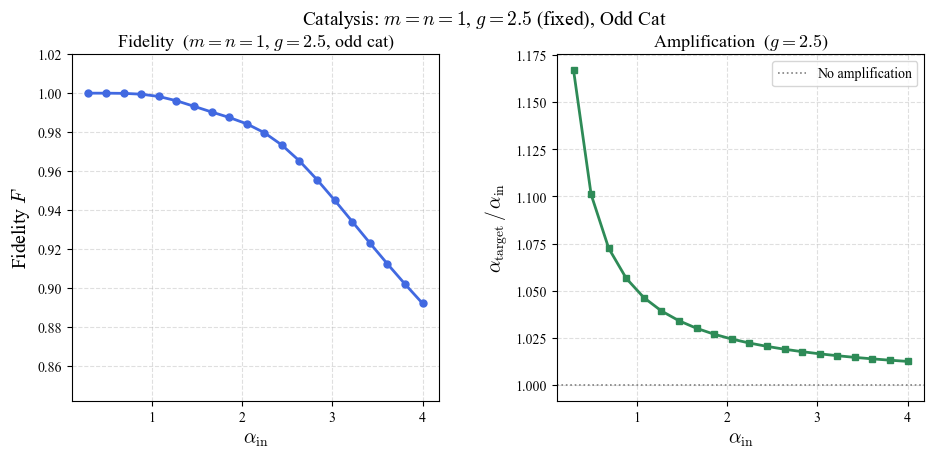

In [5]:
import numpy as np
import math
import qutip as qt
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.optimize import differential_evolution
from joblib import Parallel, delayed

mpl.rcParams['mathtext.fontset'] = 'cm'
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman']

# ============================================================
#  ★ 用户参数区
# ============================================================
N_ORDER   = 1
CAT_TYPE  = "odd"
N_DIM     = 50

G_FIXED   = 2.5      # ★ 固定 g

ALPHA_IN_MIN  = 0.3
ALPHA_IN_MAX  = 4.0
ALPHA_IN_NPTS = 20

ALPHA_TARGET_MAX_OFFSET = 3.0

RESTART_SEEDS = [42, 123, 7]

SMALL_ALPHA_THRESHOLD = 0.8
DE_MAXITER_SMALL = 150
DE_POPSIZE_SMALL = 20
DE_MAXITER_LARGE = 80
DE_POPSIZE_LARGE = 12

N_WORKERS = 4
# ============================================================


def precompute_input_terms(alpha_in, n, cat_type, N_dim):
    a    = qt.destroy(N_dim)
    adag = qt.create(N_dim)
    alpha_plus  = qt.coherent(N_dim,  alpha_in)
    alpha_minus = qt.coherent(N_dim, -alpha_in)
    phi_in = (alpha_plus + alpha_minus).unit() if cat_type == "even" \
             else (alpha_plus - alpha_minus).unit()
    phi_vec  = phi_in.full().flatten()
    a_mat    = a.full()
    adag_mat = adag.full()
    ak_phi_vecs = [phi_vec.copy()]
    vec = phi_vec.copy()
    for _ in range(1, n + 1):
        vec = a_mat @ vec
        ak_phi_vecs.append(vec.copy())
    fac_coefs = [
        (-1)**k * math.factorial(n) /
        (math.factorial(k)**2 * math.factorial(n - k))
        for k in range(n + 1)
    ]
    return ak_phi_vecs, adag_mat, fac_coefs


def precompute_cat_base(alpha_target, cat_type, N_dim):
    alpha_plus  = qt.coherent(N_dim,  alpha_target)
    alpha_minus = qt.coherent(N_dim, -alpha_target)
    base_cat = (alpha_plus + alpha_minus).unit() if cat_type == "even" \
               else (alpha_plus - alpha_minus).unit()
    return base_cat.full().flatten()


def fast_catalysis_vec(g, n, ak_phi_vecs, adag_mat, fac_coefs, N_dim):
    G      = np.sqrt(max(1 - 1.0 / g**2, 0.0))
    g_diag = g ** (-np.arange(N_dim, dtype=float))
    psi_out = np.zeros(N_dim, dtype=complex)
    for k in range(n + 1):
        vec = g_diag * ak_phi_vecs[k]
        for _ in range(k):
            vec = adag_mat @ vec
        psi_out += fac_coefs[k] * (G**(2*k)) / (g**(n - k + 1)) * vec
    norm = np.linalg.norm(psi_out)
    return psi_out / norm if norm > 1e-15 else psi_out


def squeeze_vec(cat_vec, gamma, N_dim):
    S_mat = qt.squeeze(N_dim, gamma).full()
    sv    = S_mat @ cat_vec
    norm  = np.linalg.norm(sv)
    return sv / norm if norm > 1e-15 else sv


def _optimize_one(alpha_in, g_fixed, n, cat_type, N_dim,
                  alpha_tgt_max_offset, de_maxiter, de_popsize,
                  restart_seeds, small_alpha_threshold,
                  de_maxiter_small, de_popsize_small):
    """
    g 固定，只优化 [alpha_target, r]。
    """
    ak_phi_vecs, adag_mat, fac_coefs = precompute_input_terms(
        alpha_in, n, cat_type, N_dim)

    # g 固定，提前算好输出态向量（在所有 cost() 调用里复用）
    psi_out = fast_catalysis_vec(g_fixed, n, ak_phi_vecs, adag_mat, fac_coefs, N_dim)

    is_small = alpha_in < small_alpha_threshold
    maxiter  = de_maxiter_small if is_small else de_maxiter
    popsize  = de_popsize_small if is_small else de_popsize

    bounds = [
        (alpha_in + 0.05, alpha_in + alpha_tgt_max_offset),  # alpha_target
        (0.0, 2.0),                                           # r
    ]

    def cost(x):
        alpha_target, gamma = x
        try:
            cat_vec = precompute_cat_base(alpha_target, cat_type, N_dim)
            psi_tgt = squeeze_vec(cat_vec, gamma, N_dim)
            return -abs(np.dot(psi_out.conj(), psi_tgt))**2
        except Exception:
            return 1.0

    best_F = -1.0
    best_x = None
    for seed in restart_seeds:
        res = differential_evolution(
            cost, bounds,
            strategy='best1bin',
            maxiter=maxiter,
            popsize=popsize,
            seed=seed,
            tol=1e-6,
            disp=False,
        )
        F = float(-res.fun)
        if F > best_F:
            best_F = F
            best_x = res.x

    at_opt, r_opt = best_x
    return float(alpha_in), best_F, float(at_opt), float(r_opt)


def run_scan_and_plot():
    alpha_in_arr = np.linspace(ALPHA_IN_MIN, ALPHA_IN_MAX, ALPHA_IN_NPTS)

    print("╔══════════════════════════════════════════════════════════╗")
    print(f"  m=n={N_ORDER} | {CAT_TYPE} | g 固定 = {G_FIXED}")
    print(f"  优化变量: alpha_target, r  |  重启种子: {RESTART_SEEDS}")
    print(f"  小 α_in (<{SMALL_ALPHA_THRESHOLD}): maxiter={DE_MAXITER_SMALL}, popsize={DE_POPSIZE_SMALL}")
    print("╚══════════════════════════════════════════════════════════╝\n")

    raw_results = Parallel(n_jobs=N_WORKERS, backend='loky', verbose=5)(
        delayed(_optimize_one)(
            ai, G_FIXED, N_ORDER, CAT_TYPE, N_DIM,
            ALPHA_TARGET_MAX_OFFSET,
            DE_MAXITER_LARGE, DE_POPSIZE_LARGE, RESTART_SEEDS,
            SMALL_ALPHA_THRESHOLD, DE_MAXITER_SMALL, DE_POPSIZE_SMALL
        )
        for ai in alpha_in_arr
    )

    raw_results.sort(key=lambda r: r[0])
    alpha_in_arr   = np.array([r[0] for r in raw_results])
    fidelities     = np.array([r[1] for r in raw_results])
    opt_alpha_tgts = np.array([r[2] for r in raw_results])
    opt_rs         = np.array([r[3] for r in raw_results])
    amplifications = opt_alpha_tgts / alpha_in_arr

    print(f"\n  {'α_in':>6}  {'α_tgt':>6}  {'amp':>5}  {'F':>7}  {'r':>6}")
    print(f"  {'-'*6}  {'-'*6}  {'-'*5}  {'-'*7}  {'-'*6}")
    for r in raw_results:
        ai, F, at, rv = r
        print(f"  {ai:6.3f}  {at:6.3f}  {at/ai:5.3f}  {F:7.4f}  {rv:6.3f}")

    # ── 两张图并排 ──
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
    fig.subplots_adjust(wspace=0.32)

    ax1.plot(alpha_in_arr, fidelities, 'o-', color='royalblue', lw=2, ms=5)
    ax1.set_xlabel(r'$\alpha_{\mathrm{in}}$', fontsize=14)
    ax1.set_ylabel(r'Fidelity $F$', fontsize=14)
    ax1.set_title(rf'Fidelity  ($m=n={N_ORDER}$, $g={G_FIXED}$, {CAT_TYPE} cat)',
                  fontsize=13)
    ax1.set_ylim(max(0, fidelities.min() - 0.05), 1.02)
    ax1.grid(True, ls='--', alpha=0.4)

    ax2.plot(alpha_in_arr, amplifications, 's-', color='seagreen', lw=2, ms=5)
    ax2.axhline(1.0, color='grey', ls=':', lw=1.2, label='No amplification')
    ax2.set_xlabel(r'$\alpha_{\mathrm{in}}$', fontsize=14)
    ax2.set_ylabel(r'$\alpha_{\mathrm{target}}\,/\,\alpha_{\mathrm{in}}$', fontsize=14)
    ax2.set_title(rf'Amplification  ($g={G_FIXED}$)', fontsize=13)
    ax2.legend(fontsize=10)
    ax2.grid(True, ls='--', alpha=0.4)

    fig.suptitle(
        rf"Catalysis: $m=n={N_ORDER}$, $g={G_FIXED}$ (fixed), {CAT_TYPE.capitalize()} Cat",
        fontsize=14)

    plt.savefig('catalysis_result.pdf', bbox_inches='tight', dpi=150)
    plt.savefig('catalysis_result.png', bbox_inches='tight', dpi=150)
    plt.show()


run_scan_and_plot()

╔══════════════════════════════════════════════════════════╗
  m=n=3 | even | g 固定 = 1.93
  优化变量: alpha_target, r  |  重启种子: [42, 123, 7]
  小 α_in (<0.8): maxiter=150, popsize=20
╚══════════════════════════════════════════════════════════╝



[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   9 out of  13 | elapsed:   28.9s remaining:   12.8s
[Parallel(n_jobs=4)]: Done  13 out of  13 | elapsed:   35.3s finished



    α_in   α_tgt    amp        F       r
  ------  ------  -----  -------  ------
   0.300   0.435  1.451   1.0000   0.022
   0.400   0.581  1.452   1.0000   0.039
   0.500   0.727  1.454   1.0000   0.061
   0.600   0.874  1.457   1.0000   0.089
   0.700   1.024  1.462   1.0000   0.122
   0.800   1.177  1.472   1.0000   0.161
   0.900   1.338  1.487   0.9999   0.207
   1.000   1.512  1.512   0.9997   0.262
   1.100   1.705  1.550   0.9994   0.327
   1.200   1.925  1.605   0.9986   0.405
   1.300   2.172  1.671   0.9968   0.490
   1.400   2.436  1.740   0.9921   0.577
   1.500   2.706  1.804   0.9815   0.661


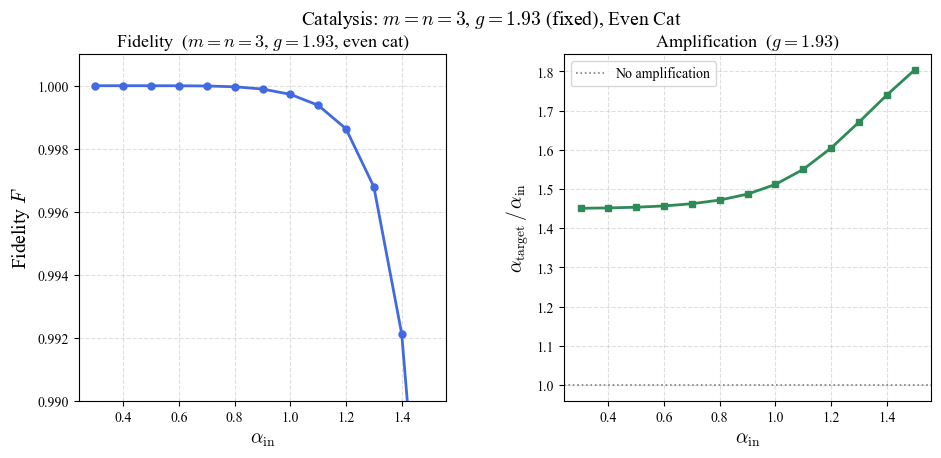

In [5]:
import numpy as np
import math
import qutip as qt
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.optimize import differential_evolution
from joblib import Parallel, delayed

mpl.rcParams['mathtext.fontset'] = 'cm'
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman']

# ============================================================
#  ★ 用户参数区
# ============================================================
N_ORDER   = 3
CAT_TYPE  = "even"
N_DIM     = 50

G_FIXED   = 1.93      # ★ 固定 g

ALPHA_IN_MIN  = 0.3
ALPHA_IN_MAX  = 1.5
ALPHA_IN_NPTS = 13

ALPHA_TARGET_MAX_OFFSET = 3.0

RESTART_SEEDS = [42, 123, 7]

SMALL_ALPHA_THRESHOLD = 0.8
DE_MAXITER_SMALL = 150
DE_POPSIZE_SMALL = 20
DE_MAXITER_LARGE = 80
DE_POPSIZE_LARGE = 12

N_WORKERS = 4
# ============================================================


def precompute_input_terms(alpha_in, n, cat_type, N_dim):
    a    = qt.destroy(N_dim)
    adag = qt.create(N_dim)
    alpha_plus  = qt.coherent(N_dim,  alpha_in)
    alpha_minus = qt.coherent(N_dim, -alpha_in)
    phi_in = (alpha_plus + alpha_minus).unit() if cat_type == "even" \
             else (alpha_plus - alpha_minus).unit()
    phi_vec  = phi_in.full().flatten()
    a_mat    = a.full()
    adag_mat = adag.full()
    ak_phi_vecs = [phi_vec.copy()]
    vec = phi_vec.copy()
    for _ in range(1, n + 1):
        vec = a_mat @ vec
        ak_phi_vecs.append(vec.copy())
    fac_coefs = [
        (-1)**k * math.factorial(n) /
        (math.factorial(k)**2 * math.factorial(n - k))
        for k in range(n + 1)
    ]
    return ak_phi_vecs, adag_mat, fac_coefs


def precompute_cat_base(alpha_target, cat_type, N_dim):
    alpha_plus  = qt.coherent(N_dim,  alpha_target)
    alpha_minus = qt.coherent(N_dim, -alpha_target)
    base_cat = (alpha_plus + alpha_minus).unit() if cat_type == "even" \
               else (alpha_plus - alpha_minus).unit()
    return base_cat.full().flatten()


def fast_catalysis_vec(g, n, ak_phi_vecs, adag_mat, fac_coefs, N_dim):
    G      = np.sqrt(max(1 - 1.0 / g**2, 0.0))
    g_diag = g ** (-np.arange(N_dim, dtype=float))
    psi_out = np.zeros(N_dim, dtype=complex)
    for k in range(n + 1):
        vec = g_diag * ak_phi_vecs[k]
        for _ in range(k):
            vec = adag_mat @ vec
        psi_out += fac_coefs[k] * (G**(2*k)) / (g**(n - k + 1)) * vec
    norm = np.linalg.norm(psi_out)
    return psi_out / norm if norm > 1e-15 else psi_out


def squeeze_vec(cat_vec, gamma, N_dim):
    S_mat = qt.squeeze(N_dim, gamma).full()
    sv    = S_mat @ cat_vec
    norm  = np.linalg.norm(sv)
    return sv / norm if norm > 1e-15 else sv


def _optimize_one(alpha_in, g_fixed, n, cat_type, N_dim,
                  alpha_tgt_max_offset, de_maxiter, de_popsize,
                  restart_seeds, small_alpha_threshold,
                  de_maxiter_small, de_popsize_small):
    """
    g 固定，只优化 [alpha_target, r]。
    """
    ak_phi_vecs, adag_mat, fac_coefs = precompute_input_terms(
        alpha_in, n, cat_type, N_dim)

    # g 固定，提前算好输出态向量（在所有 cost() 调用里复用）
    psi_out = fast_catalysis_vec(g_fixed, n, ak_phi_vecs, adag_mat, fac_coefs, N_dim)

    is_small = alpha_in < small_alpha_threshold
    maxiter  = de_maxiter_small if is_small else de_maxiter
    popsize  = de_popsize_small if is_small else de_popsize

    bounds = [
        (alpha_in + 0.05, alpha_in + alpha_tgt_max_offset),  # alpha_target
        (0.0, 2.0),                                           # r
    ]

    def cost(x):
        alpha_target, gamma = x
        try:
            cat_vec = precompute_cat_base(alpha_target, cat_type, N_dim)
            psi_tgt = squeeze_vec(cat_vec, gamma, N_dim)
            return -abs(np.dot(psi_out.conj(), psi_tgt))**2
        except Exception:
            return 1.0

    best_F = -1.0
    best_x = None
    for seed in restart_seeds:
        res = differential_evolution(
            cost, bounds,
            strategy='best1bin',
            maxiter=maxiter,
            popsize=popsize,
            seed=seed,
            tol=1e-6,
            disp=False,
        )
        F = float(-res.fun)
        if F > best_F:
            best_F = F
            best_x = res.x

    at_opt, r_opt = best_x
    return float(alpha_in), best_F, float(at_opt), float(r_opt)


def run_scan_and_plot():
    alpha_in_arr = np.linspace(ALPHA_IN_MIN, ALPHA_IN_MAX, ALPHA_IN_NPTS)

    print("╔══════════════════════════════════════════════════════════╗")
    print(f"  m=n={N_ORDER} | {CAT_TYPE} | g 固定 = {G_FIXED}")
    print(f"  优化变量: alpha_target, r  |  重启种子: {RESTART_SEEDS}")
    print(f"  小 α_in (<{SMALL_ALPHA_THRESHOLD}): maxiter={DE_MAXITER_SMALL}, popsize={DE_POPSIZE_SMALL}")
    print("╚══════════════════════════════════════════════════════════╝\n")

    raw_results = Parallel(n_jobs=N_WORKERS, backend='loky', verbose=5)(
        delayed(_optimize_one)(
            ai, G_FIXED, N_ORDER, CAT_TYPE, N_DIM,
            ALPHA_TARGET_MAX_OFFSET,
            DE_MAXITER_LARGE, DE_POPSIZE_LARGE, RESTART_SEEDS,
            SMALL_ALPHA_THRESHOLD, DE_MAXITER_SMALL, DE_POPSIZE_SMALL
        )
        for ai in alpha_in_arr
    )

    raw_results.sort(key=lambda r: r[0])
    alpha_in_arr   = np.array([r[0] for r in raw_results])
    fidelities     = np.array([r[1] for r in raw_results])
    opt_alpha_tgts = np.array([r[2] for r in raw_results])
    opt_rs         = np.array([r[3] for r in raw_results])
    amplifications = opt_alpha_tgts / alpha_in_arr

    print(f"\n  {'α_in':>6}  {'α_tgt':>6}  {'amp':>5}  {'F':>7}  {'r':>6}")
    print(f"  {'-'*6}  {'-'*6}  {'-'*5}  {'-'*7}  {'-'*6}")
    for r in raw_results:
        ai, F, at, rv = r
        print(f"  {ai:6.3f}  {at:6.3f}  {at/ai:5.3f}  {F:7.4f}  {rv:6.3f}")

    # ── 两张图并排 ──
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
    fig.subplots_adjust(wspace=0.32)

    ax1.plot(alpha_in_arr, fidelities, 'o-', color='royalblue', lw=2, ms=5)
    ax1.set_xlabel(r'$\alpha_{\mathrm{in}}$', fontsize=14)
    ax1.set_ylabel(r'Fidelity $F$', fontsize=14)
    ax1.set_title(rf'Fidelity  ($m=n={N_ORDER}$, $g={G_FIXED}$, {CAT_TYPE} cat)',
                  fontsize=13)
    ax1.set_ylim(0.99, 1.001)
    ax1.grid(True, ls='--', alpha=0.4)

    ax2.plot(alpha_in_arr, amplifications, 's-', color='seagreen', lw=2, ms=5)
    ax2.axhline(1.0, color='grey', ls=':', lw=1.2, label='No amplification')
    ax2.set_xlabel(r'$\alpha_{\mathrm{in}}$', fontsize=14)
    ax2.set_ylabel(r'$\alpha_{\mathrm{target}}\,/\,\alpha_{\mathrm{in}}$', fontsize=14)
    ax2.set_title(rf'Amplification  ($g={G_FIXED}$)', fontsize=13)
    ax2.legend(fontsize=10)
    ax2.grid(True, ls='--', alpha=0.4)

    fig.suptitle(
        rf"Catalysis: $m=n={N_ORDER}$, $g={G_FIXED}$ (fixed), {CAT_TYPE.capitalize()} Cat",
        fontsize=14)

    plt.savefig('catalysis_result.pdf', bbox_inches='tight', dpi=150)
    plt.savefig('catalysis_result.png', bbox_inches='tight', dpi=150)
    plt.show()


run_scan_and_plot()

╔══════════════════════════════════════════════════════════╗
  m=n=1 | even | g 固定 = 1.36
  α_target 范围: [0.05, 5.0]（允许缩小）
  重启种子: [42, 123, 7]
╚══════════════════════════════════════════════════════════╝



[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   35.5s
[Parallel(n_jobs=4)]: Done  18 out of  20 | elapsed:   52.7s remaining:    5.8s
[Parallel(n_jobs=4)]: Done  20 out of  20 | elapsed:   55.1s finished



    α_in   α_tgt     amp        F       r
  ------  ------  ------  -------  ------
   0.300   0.259   0.863 ▼   1.0000   0.101
   0.363   0.311   0.856 ▼   1.0000   0.145
   0.426   0.361   0.848 ▼   1.0000   0.197
   0.489   0.408   0.834 ▼   1.0000   0.251
   0.553   0.452   0.817 ▼   0.9999   0.308
   0.616   0.491   0.798 ▼   0.9996   0.365
   0.679   0.526   0.775 ▼   0.9989   0.419
   0.742   0.558   0.751 ▼   0.9975   0.470
   0.805   0.586   0.727 ▼   0.9949   0.516
   0.868   0.611   0.703 ▼   0.9902   0.558
   0.932   0.633   0.680 ▼   0.9824   0.595
   0.995   0.654   0.658 ▼   0.9705   0.628
   1.058   0.673   0.637 ▼   0.9531   0.656
   1.121   0.692   0.617 ▼   0.9287   0.680
   1.184   0.710   0.599 ▼   0.8960   0.701
   1.247   0.728   0.583 ▼   0.8539   0.719
   1.311   0.745   0.569 ▼   0.8021   0.733
   1.374   0.763   0.556 ▼   0.7409   0.745
   1.437   0.782   0.544 ▼   0.6719   0.754
   1.500   0.801   0.534 ▼   0.5975   0.762


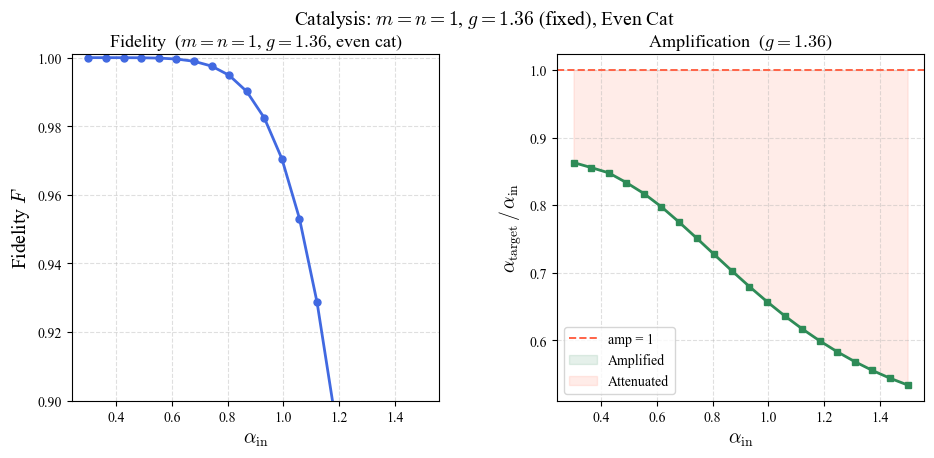

In [9]:
import numpy as np
import math
import qutip as qt
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.optimize import differential_evolution
from joblib import Parallel, delayed

mpl.rcParams['mathtext.fontset'] = 'cm'
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman']

# ============================================================
#  ★ 用户参数区
# ============================================================
N_ORDER   = 2
CAT_TYPE  = "even"
N_DIM     = 50

G_FIXED   = 1.36

ALPHA_IN_MIN  = 0.3
ALPHA_IN_MAX  = 1.5
ALPHA_IN_NPTS = 20

# alpha_target 搜索范围（绝对值，与 alpha_in 无关）
ALPHA_TARGET_MIN = 0.05   # ★ 允许小于 alpha_in
ALPHA_TARGET_MAX = 5.0    # ★ 上限

RESTART_SEEDS = [42, 123, 7]

SMALL_ALPHA_THRESHOLD = 0.8
DE_MAXITER_SMALL = 150
DE_POPSIZE_SMALL = 20
DE_MAXITER_LARGE = 80
DE_POPSIZE_LARGE = 12

N_WORKERS = 4
# ============================================================


def precompute_input_terms(alpha_in, n, cat_type, N_dim):
    a    = qt.destroy(N_dim)
    adag = qt.create(N_dim)
    alpha_plus  = qt.coherent(N_dim,  alpha_in)
    alpha_minus = qt.coherent(N_dim, -alpha_in)
    phi_in = (alpha_plus + alpha_minus).unit() if cat_type == "even" \
             else (alpha_plus - alpha_minus).unit()
    phi_vec  = phi_in.full().flatten()
    a_mat    = a.full()
    adag_mat = adag.full()
    ak_phi_vecs = [phi_vec.copy()]
    vec = phi_vec.copy()
    for _ in range(1, n + 1):
        vec = a_mat @ vec
        ak_phi_vecs.append(vec.copy())
    fac_coefs = [
        (-1)**k * math.factorial(n) /
        (math.factorial(k)**2 * math.factorial(n - k))
        for k in range(n + 1)
    ]
    return ak_phi_vecs, adag_mat, fac_coefs


def precompute_cat_base(alpha_target, cat_type, N_dim):
    alpha_plus  = qt.coherent(N_dim,  alpha_target)
    alpha_minus = qt.coherent(N_dim, -alpha_target)
    base_cat = (alpha_plus + alpha_minus).unit() if cat_type == "even" \
               else (alpha_plus - alpha_minus).unit()
    return base_cat.full().flatten()


def fast_catalysis_vec(g, n, ak_phi_vecs, adag_mat, fac_coefs, N_dim):
    G      = np.sqrt(max(1 - 1.0 / g**2, 0.0))
    g_diag = g ** (-np.arange(N_dim, dtype=float))
    psi_out = np.zeros(N_dim, dtype=complex)
    for k in range(n + 1):
        vec = g_diag * ak_phi_vecs[k]
        for _ in range(k):
            vec = adag_mat @ vec
        psi_out += fac_coefs[k] * (G**(2*k)) / (g**(n - k + 1)) * vec
    norm = np.linalg.norm(psi_out)
    return psi_out / norm if norm > 1e-15 else psi_out


def squeeze_vec(cat_vec, gamma, N_dim):
    S_mat = qt.squeeze(N_dim, gamma).full()
    sv    = S_mat @ cat_vec
    norm  = np.linalg.norm(sv)
    return sv / norm if norm > 1e-15 else sv


def _optimize_one(alpha_in, g_fixed, n, cat_type, N_dim,
                  at_min, at_max, de_maxiter, de_popsize,
                  restart_seeds, small_alpha_threshold,
                  de_maxiter_small, de_popsize_small):
    ak_phi_vecs, adag_mat, fac_coefs = precompute_input_terms(
        alpha_in, n, cat_type, N_dim)

    # g 固定，输出态只算一次
    psi_out = fast_catalysis_vec(g_fixed, n, ak_phi_vecs, adag_mat, fac_coefs, N_dim)

    is_small = alpha_in < small_alpha_threshold
    maxiter  = de_maxiter_small if is_small else de_maxiter
    popsize  = de_popsize_small if is_small else de_popsize

    bounds = [
        (at_min, at_max),  # alpha_target：无放大方向限制
        (0.0, 2.0),        # r
    ]

    def cost(x):
        alpha_target, gamma = x
        try:
            cat_vec = precompute_cat_base(alpha_target, cat_type, N_dim)
            psi_tgt = squeeze_vec(cat_vec, gamma, N_dim)
            return -abs(np.dot(psi_out.conj(), psi_tgt))**2
        except Exception:
            return 1.0

    best_F = -1.0
    best_x = None
    for seed in restart_seeds:
        res = differential_evolution(
            cost, bounds,
            strategy='best1bin',
            maxiter=maxiter,
            popsize=popsize,
            seed=seed,
            tol=1e-6,
            disp=False,
        )
        F = float(-res.fun)
        if F > best_F:
            best_F = F
            best_x = res.x

    at_opt, r_opt = best_x
    return float(alpha_in), best_F, float(at_opt), float(r_opt)


def run_scan_and_plot():
    alpha_in_arr = np.linspace(ALPHA_IN_MIN, ALPHA_IN_MAX, ALPHA_IN_NPTS)

    print("╔══════════════════════════════════════════════════════════╗")
    print(f"  m=n={N_ORDER} | {CAT_TYPE} | g 固定 = {G_FIXED}")
    print(f"  α_target 范围: [{ALPHA_TARGET_MIN}, {ALPHA_TARGET_MAX}]（允许缩小）")
    print(f"  重启种子: {RESTART_SEEDS}")
    print("╚══════════════════════════════════════════════════════════╝\n")

    raw_results = Parallel(n_jobs=N_WORKERS, backend='loky', verbose=5)(
        delayed(_optimize_one)(
            ai, G_FIXED, N_ORDER, CAT_TYPE, N_DIM,
            ALPHA_TARGET_MIN, ALPHA_TARGET_MAX,
            DE_MAXITER_LARGE, DE_POPSIZE_LARGE, RESTART_SEEDS,
            SMALL_ALPHA_THRESHOLD, DE_MAXITER_SMALL, DE_POPSIZE_SMALL
        )
        for ai in alpha_in_arr
    )

    raw_results.sort(key=lambda r: r[0])
    alpha_in_arr   = np.array([r[0] for r in raw_results])
    fidelities     = np.array([r[1] for r in raw_results])
    opt_alpha_tgts = np.array([r[2] for r in raw_results])
    opt_rs         = np.array([r[3] for r in raw_results])
    amplifications = opt_alpha_tgts / alpha_in_arr

    print(f"\n  {'α_in':>6}  {'α_tgt':>6}  {'amp':>6}  {'F':>7}  {'r':>6}")
    print(f"  {'-'*6}  {'-'*6}  {'-'*6}  {'-'*7}  {'-'*6}")
    for r in raw_results:
        ai, F, at, rv = r
        flag = " ▲" if at > ai else (" ▼" if at < ai else "  ")
        print(f"  {ai:6.3f}  {at:6.3f}  {at/ai:6.3f}{flag}  {F:7.4f}  {rv:6.3f}")

    # ── 两张图并排 ──
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
    fig.subplots_adjust(wspace=0.32)

    ax1.plot(alpha_in_arr, fidelities, 'o-', color='royalblue', lw=2, ms=5)
    ax1.set_xlabel(r'$\alpha_{\mathrm{in}}$', fontsize=14)
    ax1.set_ylabel(r'Fidelity $F$', fontsize=14)
    ax1.set_title(rf'Fidelity  ($m=n={N_ORDER}$, $g={G_FIXED}$, {CAT_TYPE} cat)',
                  fontsize=13)
    ax1.set_ylim(0.90, 1.001)
    ax1.grid(True, ls='--', alpha=0.4)

    ax2.plot(alpha_in_arr, amplifications, 's-', color='seagreen', lw=2, ms=5)
    ax2.axhline(1.0, color='tomato', ls='--', lw=1.4, label='amp = 1')
    ax2.fill_between(alpha_in_arr, amplifications, 1.0,
                     where=(amplifications >= 1.0),
                     alpha=0.12, color='seagreen', label='Amplified')
    ax2.fill_between(alpha_in_arr, amplifications, 1.0,
                     where=(amplifications < 1.0),
                     alpha=0.12, color='tomato', label='Attenuated')
    ax2.set_xlabel(r'$\alpha_{\mathrm{in}}$', fontsize=14)
    ax2.set_ylabel(r'$\alpha_{\mathrm{target}}\,/\,\alpha_{\mathrm{in}}$', fontsize=14)
    ax2.set_title(rf'Amplification  ($g={G_FIXED}$)', fontsize=13)
    ax2.legend(fontsize=10)
    ax2.grid(True, ls='--', alpha=0.4)

    fig.suptitle(
        rf"Catalysis: $m=n={N_ORDER}$, $g={G_FIXED}$ (fixed), {CAT_TYPE.capitalize()} Cat",
        fontsize=14)

    plt.savefig('catalysis_result.pdf', bbox_inches='tight', dpi=150)
    plt.savefig('catalysis_result.png', bbox_inches='tight', dpi=150)
    plt.show()


run_scan_and_plot()


  Running case: m=n=1, g=1.1


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   45.8s
[Parallel(n_jobs=4)]: Done  18 out of  20 | elapsed:  1.3min remaining:    8.4s
[Parallel(n_jobs=4)]: Done  20 out of  20 | elapsed:  1.5min finished
[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.



    α_in   α_tgt     amp        F       r
  ------  ------  ------  -------  ------
   0.300   0.220   0.733 ▼   1.0000   0.005
   0.389   0.285   0.733 ▼   1.0000   0.009
   0.479   0.352   0.734 ▼   1.0000   0.014
   0.568   0.417   0.734 ▼   1.0000   0.019
   0.658   0.483   0.734 ▼   1.0000   0.026
   0.747   0.549   0.735 ▼   1.0000   0.033
   0.837   0.615   0.735 ▼   1.0000   0.042
   0.926   0.681   0.736 ▼   1.0000   0.052
   1.016   0.748   0.736 ▼   1.0000   0.063
   1.105   0.815   0.738 ▼   0.9999   0.075
   1.195   0.883   0.739 ▼   0.9998   0.089
   1.284   0.952   0.741 ▼   0.9996   0.104
   1.374   1.022   0.744 ▼   0.9990   0.121
   1.463   1.094   0.748 ▼   0.9979   0.141
   1.553   1.169   0.753 ▼   0.9958   0.163
   1.642   1.249   0.760 ▼   0.9917   0.187
   1.732   1.333   0.770 ▼   0.9843   0.215
   1.821   1.427   0.783 ▼   0.9710   0.247
   1.911   1.531   0.801 ▼   0.9483   0.284
   2.000   1.651   0.825 ▼   0.9110   0.327

  Running case: m=n=2, g=2.8


[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   55.8s
[Parallel(n_jobs=4)]: Done  18 out of  20 | elapsed:  1.5min remaining:    9.9s
[Parallel(n_jobs=4)]: Done  20 out of  20 | elapsed:  1.6min finished
[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.



    α_in   α_tgt     amp        F       r
  ------  ------  ------  -------  ------
   0.300   0.510   1.699 ▲   1.0000   0.025
   0.389   0.662   1.700 ▲   1.0000   0.043
   0.479   0.815   1.702 ▲   1.0000   0.064
   0.568   0.969   1.705 ▲   1.0000   0.090
   0.658   1.124   1.708 ▲   1.0000   0.120
   0.747   1.279   1.712 ▲   0.9999   0.152
   0.837   1.435   1.714 ▲   0.9997   0.186
   0.926   1.586   1.713 ▲   0.9994   0.220
   1.016   1.733   1.706 ▲   0.9990   0.251
   1.105   1.873   1.695 ▲   0.9984   0.281
   1.195   2.008   1.681 ▲   0.9977   0.310
   1.284   2.138   1.665 ▲   0.9965   0.337
   1.374   2.263   1.648 ▲   0.9949   0.364
   1.463   2.381   1.627 ▲   0.9925   0.388
   1.553   2.490   1.604 ▲   0.9893   0.409
   1.642   2.589   1.577 ▲   0.9853   0.427
   1.732   2.678   1.547 ▲   0.9806   0.442
   1.821   2.756   1.514 ▲   0.9754   0.454
   1.911   2.826   1.479 ▲   0.9700   0.463
   2.000   2.887   1.443 ▲   0.9647   0.469

  Running case: m=n=3, g=2.0


[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   54.2s
[Parallel(n_jobs=4)]: Done  18 out of  20 | elapsed:  1.5min remaining:    9.7s
[Parallel(n_jobs=4)]: Done  20 out of  20 | elapsed:  1.7min finished
[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.



    α_in   α_tgt     amp        F       r
  ------  ------  ------  -------  ------
   0.300   0.517   1.724 ▲   1.0000   0.042
   0.389   0.672   1.725 ▲   1.0000   0.070
   0.479   0.829   1.731 ▲   1.0000   0.106
   0.568   0.989   1.739 ▲   1.0000   0.150
   0.658   1.152   1.752 ▲   0.9999   0.200
   0.747   1.320   1.766 ▲   0.9995   0.256
   0.837   1.488   1.778 ▲   0.9986   0.313
   0.926   1.649   1.781 ▲   0.9968   0.368
   1.016   1.798   1.770 ▲   0.9943   0.417
   1.105   1.938   1.753 ▲   0.9915   0.462
   1.195   2.074   1.736 ▲   0.9886   0.506
   1.284   2.215   1.725 ▲   0.9853   0.551
   1.374   2.368   1.724 ▲   0.9807   0.599
   1.463   2.535   1.733 ▲   0.9726   0.651
   1.553   2.717   1.750 ▲   0.9582   0.706
   1.642   2.910   1.772 ▲   0.9341   0.761
   1.732   3.109   1.796 ▲   0.8971   0.815
   1.821   3.309   1.817 ▲   0.8453   0.866
   1.911   3.504   1.834 ▲   0.7794   0.913
   2.000   3.692   1.846 ▲   0.7027   0.956

  Running case: m=n=4, g=1.65


[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   52.5s
[Parallel(n_jobs=4)]: Done  18 out of  20 | elapsed:  1.4min remaining:    9.4s
[Parallel(n_jobs=4)]: Done  20 out of  20 | elapsed:  1.6min finished



    α_in   α_tgt     amp        F       r
  ------  ------  ------  -------  ------
   0.300   0.440   1.466 ▲   1.0000   0.027
   0.389   0.571   1.467 ▲   1.0000   0.046
   0.479   0.704   1.469 ▲   1.0000   0.070
   0.568   0.837   1.472 ▲   1.0000   0.098
   0.658   0.972   1.478 ▲   1.0000   0.132
   0.747   1.111   1.487 ▲   1.0000   0.171
   0.837   1.254   1.499 ▲   1.0000   0.215
   0.926   1.404   1.515 ▲   1.0000   0.264
   1.016   1.561   1.537 ▲   0.9999   0.319
   1.105   1.728   1.563 ▲   0.9996   0.378
   1.195   1.907   1.596 ▲   0.9989   0.442
   1.284   2.100   1.635 ▲   0.9974   0.511
   1.374   2.310   1.682 ▲   0.9942   0.583
   1.463   2.537   1.734 ▲   0.9877   0.657
   1.553   2.775   1.787 ▲   0.9757   0.731
   1.642   3.016   1.837 ▲   0.9553   0.801
   1.732   3.255   1.880 ▲   0.9243   0.866
   1.821   3.485   1.914 ▲   0.8816   0.925
   1.911   3.704   1.939 ▲   0.8282   0.977
   2.000   3.912   1.956 ▲   0.7665   1.024


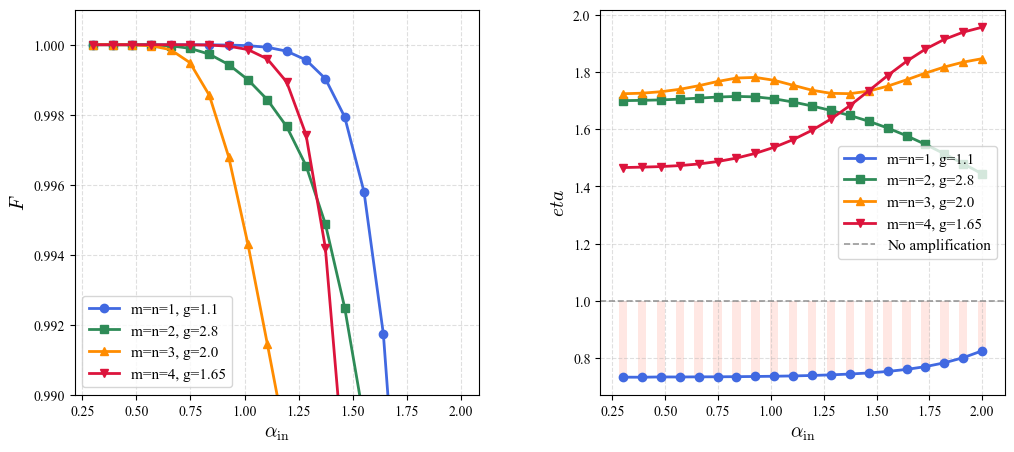

In [1]:
import numpy as np
import math
import qutip as qt
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.optimize import differential_evolution
from joblib import Parallel, delayed

mpl.rcParams['mathtext.fontset'] = 'cm'
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman']

# ============================================================
#  通用参数
# ============================================================
CAT_TYPE           = "even"
N_DIM              = 50
ALPHA_IN_MIN       = 0.3
ALPHA_IN_MAX       = 2
ALPHA_IN_NPTS      = 20
RESTART_SEEDS      = [42, 123, 7]
SMALL_ALPHA_THRESHOLD = 0.8
DE_MAXITER_SMALL   = 150
DE_POPSIZE_SMALL   = 20
DE_MAXITER_LARGE   = 80
DE_POPSIZE_LARGE   = 12
N_WORKERS          = 4

# ============================================================
#  定义四种需要比较的 case
# ============================================================
# 每个 case 是一个字典，包含：
#  'label'      : 图例文字
#  'n'          : m = n 的阶数
#  'g'          : 固定参数 g
#  'allow_atten': 是否允许 alpha_target < alpha_in（即放大倍数 < 1）
#  'at_min'     : 绝对下界（当 allow_atten=True 时使用）
#  'at_max'     : 绝对上界（当 allow_atten=True 时使用）
#  'at_offset'  : 当 allow_atten=False 时，alpha_target 上限为 alpha_in + offset，
#                  下界为 alpha_in + 0.05
cases = [
    {
        'label'      : 'm=n=1, g=1.1',
        'n'          : 1,
        'g'          : 1.1,
        'allow_atten': True,
        'at_min'     : 0.05,
        'at_max'     : 5.0,
        'at_offset'  : None
    },
    {
        'label'      : 'm=n=2, g=2.8',
        'n'          : 2,
        'g'          : 2.8,
        'allow_atten': False,
        'at_min'     : None,
        'at_max'     : None,
        'at_offset'  : 3.0
    },
    {
        'label'      : 'm=n=3, g=2.0',
        'n'          : 3,
        'g'          : 2.0,
        'allow_atten': False,
        'at_min'     : None,
        'at_max'     : None,
        'at_offset'  : 3.0
    },
    {
        'label'      : 'm=n=4, g=1.65',
        'n'          : 4,
        'g'          : 1.65,
        'allow_atten': False,
        'at_min'     : None,
        'at_max'     : None,
        'at_offset'  : 3.0
    }
]

# ============================================================
#  工具函数（与原始代码完全相同）
# ============================================================
def precompute_input_terms(alpha_in, n, cat_type, N_dim):
    a    = qt.destroy(N_dim)
    adag = qt.create(N_dim)
    alpha_plus  = qt.coherent(N_dim,  alpha_in)
    alpha_minus = qt.coherent(N_dim, -alpha_in)
    phi_in = (alpha_plus + alpha_minus).unit() if cat_type == "even" \
             else (alpha_plus - alpha_minus).unit()
    phi_vec  = phi_in.full().flatten()
    a_mat    = a.full()
    adag_mat = adag.full()
    ak_phi_vecs = [phi_vec.copy()]
    vec = phi_vec.copy()
    for _ in range(1, n + 1):
        vec = a_mat @ vec
        ak_phi_vecs.append(vec.copy())
    fac_coefs = [
        (-1)**k * math.factorial(n) /
        (math.factorial(k)**2 * math.factorial(n - k))
        for k in range(n + 1)
    ]
    return ak_phi_vecs, adag_mat, fac_coefs

def precompute_cat_base(alpha_target, cat_type, N_dim):
    alpha_plus  = qt.coherent(N_dim,  alpha_target)
    alpha_minus = qt.coherent(N_dim, -alpha_target)
    base_cat = (alpha_plus + alpha_minus).unit() if cat_type == "even" \
               else (alpha_plus - alpha_minus).unit()
    return base_cat.full().flatten()

def fast_catalysis_vec(g, n, ak_phi_vecs, adag_mat, fac_coefs, N_dim):
    G      = np.sqrt(max(1 - 1.0 / g**2, 0.0))
    g_diag = g ** (-np.arange(N_dim, dtype=float))
    psi_out = np.zeros(N_dim, dtype=complex)
    for k in range(n + 1):
        vec = g_diag * ak_phi_vecs[k]
        for _ in range(k):
            vec = adag_mat @ vec
        psi_out += fac_coefs[k] * (G**(2*k)) / (g**(n - k + 1)) * vec
    norm = np.linalg.norm(psi_out)
    return psi_out / norm if norm > 1e-15 else psi_out

def squeeze_vec(cat_vec, gamma, N_dim):
    S_mat = qt.squeeze(N_dim, gamma).full()
    sv    = S_mat @ cat_vec
    norm  = np.linalg.norm(sv)
    return sv / norm if norm > 1e-15 else sv

# ============================================================
#  优化单个 alpha_in（针对某一个 case）
# ============================================================
def optimize_one(alpha_in, case, N_dim, restart_seeds,
                 small_alpha_threshold, de_maxiter_small, de_popsize_small,
                 de_maxiter_large, de_popsize_large):
    n           = case['n']
    g           = case['g']
    allow_atten = case['allow_atten']
    at_min      = case['at_min']
    at_max      = case['at_max']
    at_offset   = case['at_offset']
    cat_type    = CAT_TYPE

    # 预计算输入态相关量（一次，供后续 cost 复用）
    ak_phi_vecs, adag_mat, fac_coefs = precompute_input_terms(alpha_in, n, cat_type, N_dim)
    psi_out = fast_catalysis_vec(g, n, ak_phi_vecs, adag_mat, fac_coefs, N_dim)

    # 根据是否允许衰减来决定搜索边界
    if allow_atten:
        bounds = [
            (at_min, at_max),   # alpha_target
            (0.0, 2.0)          # r
        ]
    else:
        # 只放大：alpha_target ∈ [alpha_in+0.05, alpha_in+at_offset]
        bounds = [
            (alpha_in + 0.05, alpha_in + at_offset),
            (0.0, 2.0)
        ]

    # 选择差分进化算法的参数
    is_small = alpha_in < small_alpha_threshold
    maxiter  = de_maxiter_small if is_small else de_maxiter_large
    popsize  = de_popsize_small if is_small else de_popsize_large

    def cost(x):
        alpha_target, gamma = x
        try:
            cat_vec = precompute_cat_base(alpha_target, cat_type, N_dim)
            psi_tgt = squeeze_vec(cat_vec, gamma, N_dim)
            return -abs(np.dot(psi_out.conj(), psi_tgt))**2
        except Exception:
            return 1.0

    best_F = -1.0
    best_x = None
    for seed in restart_seeds:
        res = differential_evolution(
            cost, bounds,
            strategy='best1bin',
            maxiter=maxiter,
            popsize=popsize,
            seed=seed,
            tol=1e-6,
            disp=False,
        )
        F = float(-res.fun)
        if F > best_F:
            best_F = F
            best_x = res.x

    at_opt, r_opt = best_x
    return float(alpha_in), best_F, float(at_opt), float(r_opt)

# ============================================================
#  主函数：对所有 alpha_in 和所有 case 运行优化，然后画图
# ============================================================
def main():
    alpha_in_arr = np.linspace(ALPHA_IN_MIN, ALPHA_IN_MAX, ALPHA_IN_NPTS)

    # 结果字典：键为 case label，值为列表 [(alpha_in, F, alpha_tgt, r), ...]
    all_results = {}

    for case in cases:
        label = case['label']
        print(f"\n{'='*60}")
        print(f"  Running case: {label}")
        print(f"{'='*60}")

        # 并行计算当前 case 的所有 alpha_in
        raw = Parallel(n_jobs=N_WORKERS, backend='loky', verbose=5)(
            delayed(optimize_one)(
                ai, case, N_DIM, RESTART_SEEDS,
                SMALL_ALPHA_THRESHOLD, DE_MAXITER_SMALL, DE_POPSIZE_SMALL,
                DE_MAXITER_LARGE, DE_POPSIZE_LARGE
            )
            for ai in alpha_in_arr
        )

        # 按 alpha_in 排序
        raw.sort(key=lambda r: r[0])
        all_results[label] = raw

        # 打印当前 case 的简要结果
        print(f"\n  {'α_in':>6}  {'α_tgt':>6}  {'amp':>6}  {'F':>7}  {'r':>6}")
        print(f"  {'-'*6}  {'-'*6}  {'-'*6}  {'-'*7}  {'-'*6}")
        for r in raw:
            ai, F, at, rv = r
            flag = " ▲" if at > ai else (" ▼" if at < ai else "  ")
            print(f"  {ai:6.3f}  {at:6.3f}  {at/ai:6.3f}{flag}  {F:7.4f}  {rv:6.3f}")

    # ========================================================
    #  画图：两个子图（Fidelity 和 Amplification）四条曲线
    # ========================================================
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    fig.subplots_adjust(wspace=0.3)

    # 颜色和标记风格
    colors = ['royalblue', 'seagreen', 'darkorange', 'crimson']
    markers = ['o', 's', '^', 'v']

    for (label, data), color, marker in zip(all_results.items(), colors, markers):
        alpha_vals = np.array([d[0] for d in data])
        fids       = np.array([d[1] for d in data])
        amps       = np.array([d[2] for d in data]) / alpha_vals  # ampli = alpha_tgt / alpha_in

        ax1.plot(alpha_vals, fids, marker=marker, color=color,
                 lw=2, ms=6, label=label)
        ax2.plot(alpha_vals, amps, marker=marker, color=color,
                 lw=2, ms=6, label=label)

    # ---- 左图：Fidelity ----
    ax1.set_xlabel(r'$\alpha_{\mathrm{in}}$', fontsize=14)
    ax1.set_ylabel(r'$F$', fontsize=14)
    ax1.set_ylim(0.96, 1.001)
    ax1.grid(True, ls='--', alpha=0.4)
    ax1.legend(fontsize=11)

    # ---- 右图：Amplification ----
    ax2.axhline(1.0, color='grey', ls='--', lw=1.2, alpha=0.8,
                label='No amplification')
    # 为允许衰减的那条曲线（m=n=1）用浅色填充衰减区域以作区分
    # 找到允许衰减的 case label
    atten_label = cases[0]['label']  # 第一个case
    for d in all_results[atten_label]:
        ai = d[0]; amp = d[2] / ai
        if amp < 1.0:
            ax2.fill_between([ai - 0.02, ai + 0.02], amp, 1.0,
                             color='tomato', alpha=0.15, edgecolor=None)
    ax2.set_xlabel(r'$\alpha_{\mathrm{in}}$', fontsize=14)
    ax2.set_ylabel(r'${eta}$', fontsize=14)
    ax2.legend(fontsize=11)
    ax2.grid(True, ls='--', alpha=0.4)

    
    plt.savefig('catalysis_comparison.pdf', bbox_inches='tight', dpi=150)
    plt.savefig('catalysis_comparison.png', bbox_inches='tight', dpi=150)
    plt.show()

if __name__ == '__main__':
    main()


  Running case: m=n=1, g=1.1


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:  1.0min
[Parallel(n_jobs=4)]: Done  25 out of  25 | elapsed:  1.8min finished
[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.



    α_in   α_tgt     amp        F       r
  ------  ------  ------  -------  ------
   0.300   0.220   0.733 ▼   1.0000   0.005
   0.350   0.256   0.732 ▼   1.0000   0.007
   0.400   0.293   0.731 ▼   1.0000   0.009
   0.450   0.330   0.734 ▼   1.0000   0.012
   0.500   0.367   0.733 ▼   1.0000   0.015
   0.550   0.404   0.734 ▼   1.0000   0.018
   0.600   0.440   0.734 ▼   1.0000   0.021
   0.650   0.477   0.734 ▼   1.0000   0.025
   0.700   0.514   0.734 ▼   1.0000   0.029
   0.750   0.551   0.735 ▼   1.0000   0.034
   0.800   0.588   0.735 ▼   1.0000   0.038
   0.850   0.625   0.735 ▼   1.0000   0.043
   0.900   0.662   0.735 ▼   1.0000   0.049
   0.950   0.699   0.736 ▼   1.0000   0.055
   1.000   0.736   0.736 ▼   1.0000   0.061
   1.050   0.774   0.737 ▼   1.0000   0.067
   1.100   0.811   0.738 ▼   0.9999   0.074
   1.150   0.849   0.738 ▼   0.9999   0.082
   1.200   0.887   0.739 ▼   0.9998   0.090
   1.250   0.925   0.740 ▼   0.9997   0.098
   1.300   0.964   0.742 ▼   0.9995

[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:  1.1min
[Parallel(n_jobs=4)]: Done  25 out of  25 | elapsed:  2.0min finished
[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.



    α_in   α_tgt     amp        F       r
  ------  ------  ------  -------  ------
   0.300   0.510   1.699 ▲   1.0000   0.025
   0.350   0.595   1.700 ▲   1.0000   0.034
   0.400   0.680   1.700 ▲   1.0000   0.045
   0.450   0.766   1.701 ▲   1.0000   0.057
   0.500   0.851   1.703 ▲   1.0000   0.070
   0.550   0.937   1.704 ▲   1.0000   0.085
   0.600   1.023   1.706 ▲   1.0000   0.100
   0.650   1.110   1.708 ▲   1.0000   0.117
   0.700   1.197   1.710 ▲   0.9999   0.135
   0.750   1.284   1.712 ▲   0.9999   0.153
   0.800   1.371   1.714 ▲   0.9998   0.172
   0.850   1.457   1.714 ▲   0.9997   0.191
   0.900   1.542   1.714 ▲   0.9995   0.210
   0.950   1.626   1.711 ▲   0.9993   0.228
   1.000   1.707   1.707 ▲   0.9991   0.246
   1.050   1.787   1.702 ▲   0.9988   0.263
   1.100   1.865   1.695 ▲   0.9985   0.280
   1.150   1.941   1.688 ▲   0.9981   0.296
   1.200   2.016   1.680 ▲   0.9976   0.312
   1.250   2.089   1.671 ▲   0.9970   0.327
   1.300   2.161   1.662 ▲   0.9963

[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:  1.1min
[Parallel(n_jobs=4)]: Done  25 out of  25 | elapsed:  2.1min finished
[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.



    α_in   α_tgt     amp        F       r
  ------  ------  ------  -------  ------
   0.300   0.435   1.451 ▲   1.0000   0.022
   0.350   0.508   1.452 ▲   1.0000   0.030
   0.400   0.581   1.452 ▲   1.0000   0.039
   0.450   0.654   1.453 ▲   1.0000   0.050
   0.500   0.727   1.454 ▲   1.0000   0.061
   0.550   0.800   1.455 ▲   1.0000   0.074
   0.600   0.874   1.457 ▲   1.0000   0.089
   0.650   0.949   1.459 ▲   1.0000   0.105
   0.700   1.024   1.462 ▲   1.0000   0.122
   0.750   1.100   1.467 ▲   1.0000   0.140
   0.800   1.177   1.472 ▲   1.0000   0.161
   0.850   1.257   1.478 ▲   0.9999   0.183
   0.900   1.338   1.487 ▲   0.9999   0.207
   0.950   1.423   1.498 ▲   0.9998   0.233
   1.000   1.512   1.512 ▲   0.9997   0.262
   1.050   1.605   1.529 ▲   0.9996   0.293
   1.100   1.705   1.550 ▲   0.9994   0.327
   1.150   1.812   1.576 ▲   0.9991   0.365
   1.200   1.925   1.605 ▲   0.9986   0.405
   1.250   2.046   1.637 ▲   0.9979   0.447
   1.300   2.172   1.671 ▲   0.9968

[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:  1.1min
[Parallel(n_jobs=4)]: Done  25 out of  25 | elapsed:  2.0min finished



    α_in   α_tgt     amp        F       r
  ------  ------  ------  -------  ------
   0.300   0.440   1.466 ▲   1.0000   0.027
   0.350   0.513   1.467 ▲   1.0000   0.037
   0.400   0.587   1.467 ▲   1.0000   0.048
   0.450   0.661   1.468 ▲   1.0000   0.061
   0.500   0.735   1.470 ▲   1.0000   0.076
   0.550   0.809   1.472 ▲   1.0000   0.092
   0.600   0.885   1.474 ▲   1.0000   0.109
   0.650   0.960   1.477 ▲   1.0000   0.129
   0.700   1.037   1.482 ▲   1.0000   0.149
   0.750   1.115   1.487 ▲   1.0000   0.172
   0.800   1.195   1.493 ▲   1.0000   0.196
   0.850   1.276   1.501 ▲   1.0000   0.222
   0.900   1.359   1.510 ▲   1.0000   0.249
   0.950   1.444   1.520 ▲   0.9999   0.278
   1.000   1.532   1.532 ▲   0.9999   0.309
   1.050   1.624   1.546 ▲   0.9998   0.341
   1.100   1.718   1.562 ▲   0.9996   0.375
   1.150   1.816   1.579 ▲   0.9993   0.410
   1.200   1.918   1.598 ▲   0.9989   0.446
   1.250   2.024   1.619 ▲   0.9982   0.484
   1.300   2.136   1.643 ▲   0.9970

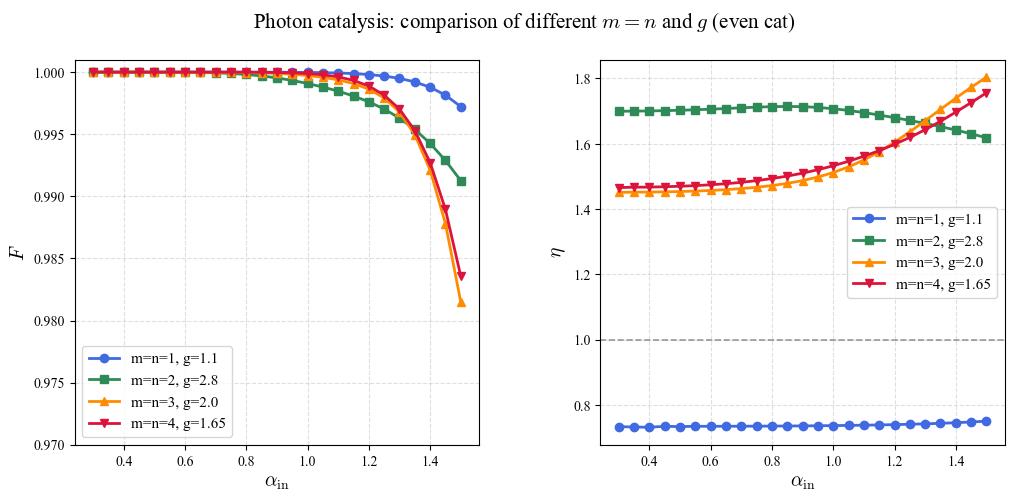

In [5]:
import numpy as np
import math
import qutip as qt
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.optimize import differential_evolution
from joblib import Parallel, delayed

mpl.rcParams['mathtext.fontset'] = 'cm'
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman']

# ============================================================
#  通用参数
# ============================================================
CAT_TYPE           = "even"
N_DIM              = 50
ALPHA_IN_MIN       = 0.3
ALPHA_IN_MAX       = 1.5
ALPHA_IN_NPTS      = 25
RESTART_SEEDS      = [42, 123, 7]
SMALL_ALPHA_THRESHOLD = 0.8
DE_MAXITER_SMALL   = 150
DE_POPSIZE_SMALL   = 20
DE_MAXITER_LARGE   = 80
DE_POPSIZE_LARGE   = 12
N_WORKERS          = 4

# ============================================================
#  定义四种需要比较的 case
# ============================================================
cases = [
    {
        'label'      : 'm=n=1, g=1.1',
        'n'          : 1,
        'g'          : 1.1,
        'allow_atten': True,
        'at_min'     : 0.05,
        'at_max'     : 5.0,
        'at_offset'  : None
    },
    {
        'label'      : 'm=n=2, g=2.8',
        'n'          : 2,
        'g'          : 2.8,
        'allow_atten': False,
        'at_min'     : None,
        'at_max'     : None,
        'at_offset'  : 3.0
    },
    {
        'label'      : 'm=n=3, g=2.0',
        'n'          : 3,
        'g'          : 1.93,
        'allow_atten': False,
        'at_min'     : None,
        'at_max'     : None,
        'at_offset'  : 3.0
    },
    {
        'label'      : 'm=n=4, g=1.65',
        'n'          : 4,
        'g'          : 1.65,
        'allow_atten': False,
        'at_min'     : None,
        'at_max'     : None,
        'at_offset'  : 3.0
    }
]

# ============================================================
#  工具函数
# ============================================================
def precompute_input_terms(alpha_in, n, cat_type, N_dim):
    a    = qt.destroy(N_dim)
    adag = qt.create(N_dim)
    alpha_plus  = qt.coherent(N_dim,  alpha_in)
    alpha_minus = qt.coherent(N_dim, -alpha_in)
    phi_in = (alpha_plus + alpha_minus).unit() if cat_type == "even" \
             else (alpha_plus - alpha_minus).unit()
    phi_vec  = phi_in.full().flatten()
    a_mat    = a.full()
    adag_mat = adag.full()
    ak_phi_vecs = [phi_vec.copy()]
    vec = phi_vec.copy()
    for _ in range(1, n + 1):
        vec = a_mat @ vec
        ak_phi_vecs.append(vec.copy())
    fac_coefs = [
        (-1)**k * math.factorial(n) /
        (math.factorial(k)**2 * math.factorial(n - k))
        for k in range(n + 1)
    ]
    return ak_phi_vecs, adag_mat, fac_coefs

def precompute_cat_base(alpha_target, cat_type, N_dim):
    alpha_plus  = qt.coherent(N_dim,  alpha_target)
    alpha_minus = qt.coherent(N_dim, -alpha_target)
    base_cat = (alpha_plus + alpha_minus).unit() if cat_type == "even" \
               else (alpha_plus - alpha_minus).unit()
    return base_cat.full().flatten()

def fast_catalysis_vec(g, n, ak_phi_vecs, adag_mat, fac_coefs, N_dim):
    G      = np.sqrt(max(1 - 1.0 / g**2, 0.0))
    g_diag = g ** (-np.arange(N_dim, dtype=float))
    psi_out = np.zeros(N_dim, dtype=complex)
    for k in range(n + 1):
        vec = g_diag * ak_phi_vecs[k]
        for _ in range(k):
            vec = adag_mat @ vec
        psi_out += fac_coefs[k] * (G**(2*k)) / (g**(n - k + 1)) * vec
    norm = np.linalg.norm(psi_out)
    return psi_out / norm if norm > 1e-15 else psi_out

def squeeze_vec(cat_vec, gamma, N_dim):
    S_mat = qt.squeeze(N_dim, gamma).full()
    sv    = S_mat @ cat_vec
    norm  = np.linalg.norm(sv)
    return sv / norm if norm > 1e-15 else sv

# ============================================================
#  优化单个 alpha_in（针对某一个 case）
# ============================================================
def optimize_one(alpha_in, case, N_dim, restart_seeds,
                 small_alpha_threshold, de_maxiter_small, de_popsize_small,
                 de_maxiter_large, de_popsize_large):
    n           = case['n']
    g           = case['g']
    allow_atten = case['allow_atten']
    at_min      = case['at_min']
    at_max      = case['at_max']
    at_offset   = case['at_offset']
    cat_type    = CAT_TYPE

    ak_phi_vecs, adag_mat, fac_coefs = precompute_input_terms(alpha_in, n, cat_type, N_dim)
    psi_out = fast_catalysis_vec(g, n, ak_phi_vecs, adag_mat, fac_coefs, N_dim)

    if allow_atten:
        bounds = [
            (at_min, at_max),   # alpha_target
            (0.0, 2.0)          # r
        ]
    else:
        bounds = [
            (alpha_in + 0.05, alpha_in + at_offset),
            (0.0, 2.0)
        ]

    is_small = alpha_in < small_alpha_threshold
    maxiter  = de_maxiter_small if is_small else de_maxiter_large
    popsize  = de_popsize_small if is_small else de_popsize_large

    def cost(x):
        alpha_target, gamma = x
        try:
            cat_vec = precompute_cat_base(alpha_target, cat_type, N_dim)
            psi_tgt = squeeze_vec(cat_vec, gamma, N_dim)
            return -abs(np.dot(psi_out.conj(), psi_tgt))**2
        except Exception:
            return 1.0

    best_F = -1.0
    best_x = None
    for seed in restart_seeds:
        res = differential_evolution(
            cost, bounds,
            strategy='best1bin',
            maxiter=maxiter,
            popsize=popsize,
            seed=seed,
            tol=1e-6,
            disp=False,
        )
        F = float(-res.fun)
        if F > best_F:
            best_F = F
            best_x = res.x

    at_opt, r_opt = best_x
    return float(alpha_in), best_F, float(at_opt), float(r_opt)

# ============================================================
#  主函数
# ============================================================
def main():
    alpha_in_arr = np.linspace(ALPHA_IN_MIN, ALPHA_IN_MAX, ALPHA_IN_NPTS)
    all_results = {}

    for case in cases:
        label = case['label']
        print(f"\n{'='*60}")
        print(f"  Running case: {label}")
        print(f"{'='*60}")

        raw = Parallel(n_jobs=N_WORKERS, backend='loky', verbose=5)(
            delayed(optimize_one)(
                ai, case, N_DIM, RESTART_SEEDS,
                SMALL_ALPHA_THRESHOLD, DE_MAXITER_SMALL, DE_POPSIZE_SMALL,
                DE_MAXITER_LARGE, DE_POPSIZE_LARGE
            )
            for ai in alpha_in_arr
        )

        raw.sort(key=lambda r: r[0])
        all_results[label] = raw

        print(f"\n  {'α_in':>6}  {'α_tgt':>6}  {'amp':>6}  {'F':>7}  {'r':>6}")
        print(f"  {'-'*6}  {'-'*6}  {'-'*6}  {'-'*7}  {'-'*6}")
        for r in raw:
            ai, F, at, rv = r
            flag = " ▲" if at > ai else (" ▼" if at < ai else "  ")
            print(f"  {ai:6.3f}  {at:6.3f}  {at/ai:6.3f}{flag}  {F:7.4f}  {rv:6.3f}")

    # ========================================================
    #  画图（所有 case 计算完毕后）
    # ========================================================
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    fig.subplots_adjust(wspace=0.3)

    colors = ['royalblue', 'seagreen', 'darkorange', 'crimson']
    markers = ['o', 's', '^', 'v']

    for (label, data), color, marker in zip(all_results.items(), colors, markers):
        alpha_vals = np.array([d[0] for d in data])
        fids       = np.array([d[1] for d in data])
        amps       = np.array([d[2] for d in data]) / alpha_vals

        ax1.plot(alpha_vals, fids, marker=marker, color=color,
                 lw=2, ms=6, label=label)
        ax2.plot(alpha_vals, amps, marker=marker, color=color,
                 lw=2, ms=6, label=label)

    ax1.set_xlabel(r'$\alpha_{\mathrm{in}}$', fontsize=14)
    ax1.set_ylabel(r'$F$', fontsize=14)
    ax1.set_ylim(0.97, 1.01)
    ax1.grid(True, ls='--', alpha=0.4)
    ax1.legend(fontsize=11)
    ax1.text(0.01, 0.99, '(a)', transform=axs[1].transAxes, fontsize=24, va='top')

    ax2.axhline(1.0, color='grey', ls='--', lw=1.2, alpha=0.8)
    ax2.set_xlabel(r'$\alpha_{\mathrm{in}}$', fontsize=14)
    ax2.set_ylabel(r'$\eta$', fontsize=14)
    ax2.legend(fontsize=11)
    ax2.grid(True, ls='--', alpha=0.4)
    ax2.text(0.01, 0.99, '(b)', transform=axs[1].transAxes, fontsize=24, va='top')

    plt.savefig('catalysis_comparison.pdf', bbox_inches='tight', dpi=150)
    plt.savefig('catalysis_comparison.png', bbox_inches='tight', dpi=150)
    plt.show()

if __name__ == '__main__':
    main()

C:\Users\YaoXiaoxi\AppData\Local\Temp\ipykernel_53284\2485483479.py:133: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  W_x_proj = np.trapz(W, PVEC, axis=0)
C:\Users\YaoXiaoxi\AppData\Local\Temp\ipykernel_53284\2485483479.py:134: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  W_p_proj = np.trapz(W, XVEC, axis=1)


图像已成功保存为 Wigner_2D_catalysis.png


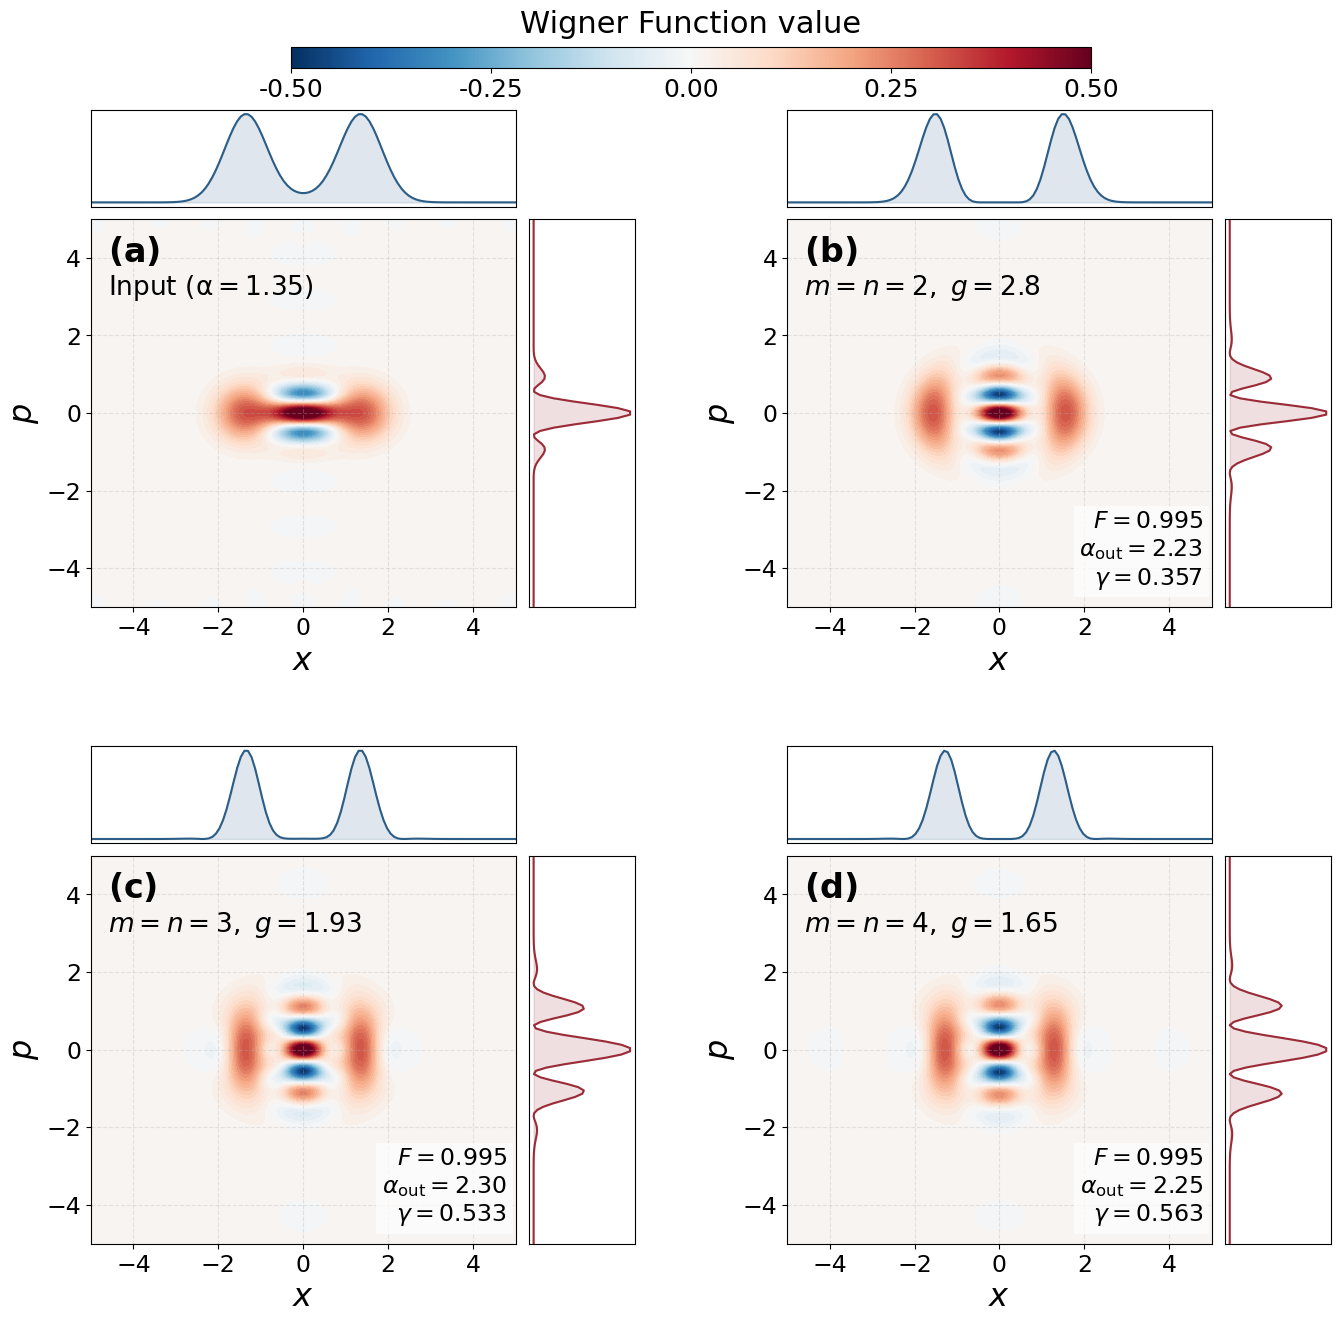

In [9]:
import numpy as np
import qutip as qt
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib import gridspec
from matplotlib.cm import ScalarMappable
from math import factorial

# ============================================================
#  全局尺寸及字号设置 (根据截图提取)
# ============================================================
FIG_SIZE = (16, 14)             # 画布整体物理尺寸 (宽, 高)
LABEL_SIZE = 23                 # x, p 坐标轴标签大小
TICK_SIZE = 17                  # 主图坐标轴数字刻度大小
SUBPLOT_LABEL_SIZE = 24         # (a)(b)(c)(d) 角标字体大小
CASE_LABEL_SIZE = 19            # 左上角物理参数 (m=, n=, g=...) 文本大小
EXTRA_INFO_SIZE = 17            # 右上角额外信息 (F=, alpha_out=...) 文本框大小
CBAR_TITLE_SIZE = 22            # 顶部色条标题大小
CBAR_TICK_SIZE = 18             # 顶部色条数字刻度大小

# ============================================================
#  参数设置
# ============================================================
N_DIM = 30
CAT_TYPE = "even"
XVEC = np.linspace(-5, 5, 120)
PVEC = np.linspace(-5, 5, 120)
X, P = np.meshgrid(XVEC, PVEC)

cases = [
    {
        'label': r'$m=n=2,\ g=2.8$', 
        'n': 2, 'g': 2.8, 
        'extra_info': '$F=0.995$\n$\\alpha_{\\mathrm{out}}=2.23$\n$\\gamma=0.357$'
    },
    {
        'label': r'$m=n=3,\ g=1.93$', 
        'n': 3, 'g': 1.93, 
        'extra_info': '$F=0.995$\n$\\alpha_{\\mathrm{out}}=2.30$\n$\\gamma=0.533$'
    },
    {
        'label': r'$m=n=4,\ g=1.65$', 
        'n': 4, 'g': 1.65, 
        'extra_info': '$F=0.995$\n$\\alpha_{\\mathrm{out}}=2.25$\n$\\gamma=0.563$'
    },
]

# ============================================================
#  工具函数
# ============================================================
def precompute_input_terms(alpha_in, n, cat_type, N_dim):
    a = qt.destroy(N_dim)
    adag = qt.create(N_dim)
    alpha_plus  = qt.coherent(N_dim, alpha_in)
    alpha_minus = qt.coherent(N_dim, -alpha_in)
    phi_in = (alpha_plus + alpha_minus).unit() if cat_type == "even" \
             else (alpha_plus - alpha_minus).unit()
    phi_vec  = phi_in.full().flatten()
    a_mat    = a.full()
    adag_mat = adag.full()
    ak_phi_vecs = [phi_vec.copy()]
    vec = phi_vec.copy()
    for _ in range(1, n + 1):
        vec = a_mat @ vec
        ak_phi_vecs.append(vec.copy())
    fac_coefs = [
        (-1)**k * factorial(n) / (factorial(k)**2 * factorial(n - k))
        for k in range(n + 1)
    ]
    return ak_phi_vecs, adag_mat, fac_coefs

def fast_catalysis_vec(g, n, ak_phi_vecs, adag_mat, fac_coefs, N_dim):
    G = np.sqrt(max(1 - 1.0 / g**2, 0.0))
    g_diag = g ** (-np.arange(N_dim, dtype=float))
    psi_out = np.zeros(N_dim, dtype=complex)
    for k in range(n + 1):
        vec = g_diag * ak_phi_vecs[k]
        for _ in range(k):
            vec = adag_mat @ vec
        psi_out += fac_coefs[k] * (G**(2*k)) / (g**(n - k + 1)) * vec
    norm = np.linalg.norm(psi_out)
    return psi_out / norm if norm > 1e-15 else psi_out

def compute_input_state(alpha_in, N_dim):
    return (qt.coherent(N_dim, alpha_in) + qt.coherent(N_dim, -alpha_in)).unit()

def compute_output_state(alpha_in, n, g, N_dim):
    ak_phi_vecs, adag_mat, fac_coefs = precompute_input_terms(alpha_in, n, CAT_TYPE, N_dim)
    vec = fast_catalysis_vec(g, n, ak_phi_vecs, adag_mat, fac_coefs, N_dim)
    return qt.Qobj(vec)

# ============================================================
#  计算 Wigner 函数
# ============================================================
alpha_fixed = 1.35

psi_in = compute_input_state(alpha_fixed, N_DIM)
W_in = qt.wigner(psi_in, XVEC, PVEC, g=2)

W_outs = []
for case in cases:
    psi_out = compute_output_state(alpha_fixed, case['n'], case['g'], N_DIM)
    W_outs.append(qt.wigner(psi_out, XVEC, PVEC, g=2))

Wigner_list = [W_in] + W_outs

norm = Normalize(vmin=-0.5, vmax=0.5)

# ============================================================
#  二维 Wigner 图及投影逻辑
# ============================================================
# 应用截图中的 FIG_SIZE
fig = plt.figure(figsize=FIG_SIZE)

outer_gs = gridspec.GridSpec(
    2, 2,
    wspace=0.28,
    hspace=0.28,
    top=0.92
)

base_labels = [
    r'$\mathrm{Input\ (\alpha=1.35)}$',
    cases[0]['label'],
    cases[1]['label'],
    cases[2]['label']
]

panel_tags = [r'$\mathbf{(a)}$', r'$\mathbf{(b)}$', r'$\mathbf{(c)}$', r'$\mathbf{(d)}$']

for idx, (W, label) in enumerate(zip(Wigner_list, base_labels)):

    W_x_proj = np.trapz(W, PVEC, axis=0)
    W_p_proj = np.trapz(W, XVEC, axis=1)

    inner_gs = gridspec.GridSpecFromSubplotSpec(
        2, 2,
        subplot_spec=outer_gs[idx],
        width_ratios=[4, 1],
        height_ratios=[1, 4],
        hspace=0.05,
        wspace=0.05
    )

    # =====================================
    # x 投影
    # =====================================
    ax_top = fig.add_subplot(inner_gs[0, 0])
    ax_top.plot(XVEC, W_x_proj, color='#2b5d87', linewidth=1.5)
    ax_top.fill_between(XVEC, W_x_proj, 0, color='#2b5d87', alpha=0.15)
    ax_top.set_xlim(-5, 5)
    ax_top.set_xticks([])
    ax_top.set_yticks([])
    ax_top.grid(True, linestyle='--', alpha=0.3)

    # =====================================
    # 主图
    # =====================================
    ax_main = fig.add_subplot(inner_gs[1, 0])
    contour = ax_main.contourf(
        XVEC, PVEC, W,
        levels=60,
        cmap='RdBu_r',
        norm=norm
    )

    ax_main.set_xlim(-5, 5)
    ax_main.set_ylim(-5, 5)
    
    # 应用 LABEL_SIZE
    ax_main.set_xlabel('$x$', fontsize=LABEL_SIZE, fontweight='bold')
    ax_main.set_ylabel('$p$', fontsize=LABEL_SIZE, fontweight='bold')
    # 应用 TICK_SIZE
    ax_main.tick_params(labelsize=TICK_SIZE)

    # 应用 SUBPLOT_LABEL_SIZE
    ax_main.text(
        -4.6, 4.6, panel_tags[idx],
        fontsize=SUBPLOT_LABEL_SIZE, ha='left', va='top'
    )

    # 应用 CASE_LABEL_SIZE
    ax_main.text(
        -4.6, 3.6, label,
        fontsize=CASE_LABEL_SIZE, ha='left', va='top'
    )

    # 右下角添加具体参数
    if idx > 0:
        # 应用 EXTRA_INFO_SIZE
        ax_main.text(
            4.8, -4.6, cases[idx-1]['extra_info'],  # 将 y 坐标从 4.4 改为 -4.6 (接近底部边界)
            fontsize=EXTRA_INFO_SIZE,
            ha='right', va='bottom',                # 垂直对齐方式改为 'bottom'
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.7)
        )

    ax_main.grid(True, linestyle='--', alpha=0.3)

    # =====================================
    # p 投影
    # =====================================
    ax_right = fig.add_subplot(inner_gs[1, 1])
    ax_right.plot(W_p_proj, PVEC, color='#9a2b37', linewidth=1.5)
    ax_right.fill_betweenx(PVEC, 0, W_p_proj, color='#9a2b37', alpha=0.15)
    ax_right.set_ylim(-5, 5)
    ax_right.set_xticks([])
    ax_right.set_yticks([])
    ax_right.grid(True, linestyle='--', alpha=0.3)

# ============================================================
# Colorbar 调整
# ============================================================
sm = ScalarMappable(norm=norm, cmap='RdBu_r')
sm.set_array([])

cbar_ax = fig.add_axes([0.25, 0.95, 0.5, 0.015])
cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
# 应用 CBAR_TITLE_SIZE
cbar.set_label("Wigner Function value", fontsize=CBAR_TITLE_SIZE, labelpad=10, loc='center')
cbar.ax.xaxis.set_label_position('top')

tick_vals = np.linspace(-0.5, 0.5, 5)
cbar.set_ticks(tick_vals)
cbar.set_ticklabels([f"{v:.2f}" for v in tick_vals])
# 应用 CBAR_TICK_SIZE
cbar.ax.tick_params(labelsize=CBAR_TICK_SIZE)

plt.savefig('Wigner_2D_catalysis.png', dpi=300, bbox_inches='tight')
print("图像已成功保存为 Wigner_2D_catalysis.png")
plt.show()